# Classify Hand-Written Digits using Multi-Layer Perceptron Neural Network
This notebook implements a fully connected Multi-Layer Perceptron (MLP) using only NumPy to solve the 10-class handwritten digit classification problem on the MNIST dataset. 
The goal is to build, train, and evaluate a neural network from first principles without relying on deep learning frameworks like PyTorch or TensorFlow.


## 1. Prepare Data
The MNIST database (Modified National Institute of Standards and Technology database) is a classic benchmark dataset of 70,000 grayscale handwritten digit images (0 through 9) widely used to train and test image processing and machine learning models. 
Often called the "Hello World" of machine learning, it was created in 1998 by Yann LeCun, Corinna Cortes, and Christopher Burges by combining and preprocessing samples from the original NIST datasets.

- Total Images: 70,000 grayscale images.
- Training Set: 60,000 images.
- Test Set: 10,000 images.
- Image Size: 28 × 28 pixels (784 total features per image).
- Pixel Values: Range from 0 (white background) to 255 (black digit).
- Classes: 10 distinct digits (0 through 9), each paired with a ground-truth label.

100.0%
100.0%
100.0%
100.0%


Number of training samples: 60000
Number of validation samples: 10000
Feature shape: (784,)
Classes: ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


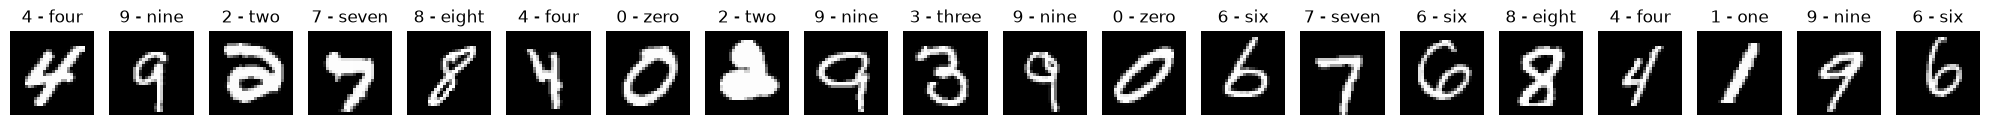

In [1]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms.v2 import Compose, ToImage, ToDtype
import numpy as np
import matplotlib.pyplot as plt

# Construct pre-processing pipeline
feature_transform_pipeline = Compose([
    ToImage(),
    ToDtype(torch.float32, scale=True),
    torch.flatten,
    torch.Tensor.numpy,
])
label_transform_pipeline = Compose([
    lambda x:torch.tensor([x]),
    lambda x:torch.nn.functional.one_hot(x,10),
    torch.squeeze,
    torch.Tensor.numpy,
])

# Download datasets
dataset_train = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=feature_transform_pipeline,
    target_transform=label_transform_pipeline,
)

dataset_val = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=feature_transform_pipeline,
    target_transform=label_transform_pipeline,
)
print(f"Number of training samples: {len(dataset_train)}")
print(f"Number of validation samples: {len(dataset_val)}")
print(f"Feature shape: {dataset_train[0][0].shape}")
print(f"Classes: {dataset_train.classes}")

# Create dataloaders
batch_size = 128
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)
dataloader_val = DataLoader(dataset_val, batch_size=100000, shuffle=True)


# Visualize data samples
sample_batch = next(iter(dataloader_train))
fig, axs = plt.subplots(1, 20, figsize=(20, 4))
for i in range(20):
    sample_img = sample_batch[0][i].numpy().reshape(28, 28)  # reconstruct image to (H, W) format
    sample_cls = dataset_train.classes[sample_batch[1][i].numpy().argmax()]  # take the index of the hot code
    axs[i] = plt.subplot(1, 20, i + 1)
    axs[i].set_title(sample_cls)
    axs[i].axis('off')
    axs[i].imshow(sample_img, cmap='gray')  # image is already in (H, W, C) format
plt.tight_layout()

## 2. Construct Multi-Layer Perceptron Model

### 2.1. Initialize Parameters
An MLP model is governed by $L$ sets of $\mathbf{W}^{[l]}$ s and $\mathbf{b}^{[l]}$ s.
Assume $\mathbf{X}^{[l-1]}$ has $N_{l-1}$ features and $\mathbf{X}^{[l]}$ has $N_{l}$ features, $\mathbf{W}^{[l]}$ needs to be a matrix with shape $(N_l, N_{l-1})$, and $\mathbf{b}^{[l]}$ needs to be a row vector with shape $(1, N_l)$.


In [2]:
def init_params(in_dims: int, hidden_dims: tuple, out_dims: int) -> dict:
    """
    Initialize the parameters of the MLP model.
    Args:
        in_dims: number of input dimensions.
        hidden_dims: tuple/list of hidden layer dimensions.
        out_dims: number of output dimensions.
    Returns:
        params: dictionary containing the initialized weights and biases.
    """
    layer_dims = [in_dims] + list(hidden_dims) + [out_dims]
    params = {}
    for l in range(len(layer_dims) - 1):
        params[f'W{l+1}'] = np.random.normal(0, 0.01, (layer_dims[l+1], layer_dims[l]))
        params[f'b{l+1}'] = np.random.normal(0, 0.01, (1, layer_dims[l+1]))
    return params

# Sanity check
params_dummy = init_params(in_dims=sample_batch[0].numpy().shape[1], hidden_dims=(4, 3), out_dims=sample_batch[1].numpy().shape[1])
for key in params_dummy:
    print(f"{key} shape: {params_dummy[key].shape}")


W1 shape: (4, 784)
b1 shape: (1, 4)
W2 shape: (3, 4)
b2 shape: (1, 3)
W3 shape: (10, 3)
b3 shape: (1, 10)


### 2.2 - Feature Transformations
A Multi-Layer Perceptron (MLP) model is composed with multiple layers of features, $\mathbf{X}^{[l]}$ s and $\mathbf{Z}^{[l]}$ s. 
The features of the previous layers, ${[l-1]}$ will be transformed (by a stack of a linear function and a non-linear activation function) to the features in the next layer, ${[l]} \text{, where } l \in {1, 2, \dots, L}$. 

$$
\begin{equation}
    \mathbf{X}^{[l]} = a(\mathbf{X}^{[l-1]} \cdot \mathbf{W}^{[l]T} + \mathbf{b}^{[l]})
\end{equation}
$$

The input layer can be defined as $\mathbf{X}^{[0]}$, and the output layer can be defined as $\hat{\mathbf{Y}} = \mathbf{X}^{[L]}$, where $L$ is the index of the last layer.


A non-linear activation function will be applied on $\mathbf{Z}^{[l]}$ to form new features $\mathbf{X}^{[l]}$ as the $l$-th layer in an MLP model.
Commonly used activations are:

- Sigmoid
$$x = \sigma (z) = \frac{1}{1 + e^{-z}}$$

- Hyperbolic Tangent
$$x = \tanh (z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$$

- Rectified Linear Unit
$$
x = \text{ReLU}(z) = 
    \begin{cases}
        0   & z \leq 0 \\
        z   & z > 0
    \end{cases}
$$

- Leaky ReLU
$$
x = \text{LeakyReLU}(z; a \geq 0) = 
    \begin{cases}
        az   & z \leq 0 \\
        z   & z > 0
    \end{cases}
$$

- Softmax
For a multi-class classification problem, we will want to encode $\mathbf{Z}^{[L]}$ into probability distributions.

$$\hat{\mathbf{y}}_i = \frac{e^{\mathbf{z}^{[L]}_i}}{\sum^C_{i=1} e^{\mathbf{z}^{[L]}_i}}$$

The maxtrix $\mathbf{Z}^{[L]}$ has shape: $(M, C)$, where $M$ is the number of samples, $C$ is the number of classes. 
When applying softmax activation, we only want it to deal with each row of $\mathbf{Z}^{[L]}$, or perform it on the last dimension (axis) of $\mathbf{Z}^{[L]}$.



In [3]:
def sigmoid(z):
    """ Sigmoid function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return 1 / (1 + np.exp(-z))

def relu(z):
    """ ReLU function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return np.maximum(0, z)

def leaky_relu(z, a=0.05):
    """ Leaky ReLU function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
        a: constant, a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return np.where(z > 0, z, a * z)

def softmax(z):
    """ Softmax function
    Args:
        z: independent variable, 2d array with shape (# samples, # features)
    Returns:
        probabilities: dependent variable, 2d array with shape (# samples, # features)
    """
    probabilities = np.exp(z) / np.sum(np.exp(z), axis=1, keepdims=True)
    return probabilities


def linear(in_features, weights, biases):
    """ Linear function
    Args:
        in_features: input feature matrix, 2d array with shape (# samples, # input features)
        weights: weight parameter matrix, 2d array with shape (# next layer features , # input features)
        biases: bias parameter vector, 2d array with shape (1, # next layer features)
    Returns:
        out_features: linear model output feature matrix, 2d array with shape (# samples, # next layer features)
    """
    out_features = in_features @ weights.T + biases
    return out_features

def forward(in_features, params, hidden_activation, out_activation="softmax"):
    """ Forward function
    Args:
        in_features: feature matrix, 2d array with shape (# samples, # pixels)
        params: a dictionary of weights and biases
            params = {
                'W1': weight matrix of the first layer, 2d array with shape (# hidden features in 1st layer, # input features)
                'b1': bias vector of the first layer, 2d array with shape (1, # hidden features in 1st layer)
                ...
                'Wi': weight matrix of the i-th layer, 2d array with shape (# hidden features in i-th layer, # hidden features in (i-1)-th layer)
                'bi': bias vector of the i-th layer, 2d array with shape (1, # hidden features in i-th layer)
                ...
                'WL': weight matrix of the last layer, 2d array with shape (# hidden features in output layer, # hidden features in (L-1)-th layer)
                'bL': bias vector of the last layer, 2d array with shape (1, # output features)
            }
        hidden_activation: activation function for hidden layers, could be sigmoid, tanh, relu, leaky relu etc. If None, no activation will be applied.
        out_activation: activation function for output layer, could be sigmoid, softmax, etc. If None, no activation will be applied.
    Returns:
        predictions: predicted probabilities, a column vector or 2d array with shape (# samples, # output features)
        cache: linear transformed and activated features
    """

    num_layers = len(params) // 2  # number of layers
    # Input layer
    cache = {}
    cache['X0'] = in_features
    # Hidden layers
    for i in range(num_layers - 1):
        cache[f'Z{i+1}'] = linear(cache[f'X{i}'], params[f'W{i+1}'], params[f'b{i+1}'])
        if hidden_activation=="relu":
            cache[f'X{i+1}'] = relu(cache[f'Z{i+1}'])
        elif hidden_activation=="leaky_relu":
            cache[f'X{i+1}'] = leaky_relu(cache[f'Z{i+1}'])
        elif hidden_activation=="sigmoid":
            cache[f'X{i+1}'] = sigmoid(cache[f'Z{i+1}'])
        elif hidden_activation=="tanh":
            cache[f'X{i+1}'] = np.tanh(cache[f'Z{i+1}'])
        else:
            cache[f'X{i+1}'] = cache[f'Z{i+1}']  # no activation
    # Output layer
    cache[f'Z{num_layers}'] = linear(cache[f'X{num_layers-1}'], params[f'W{num_layers}'], params[f'b{num_layers}'])
    if out_activation=="softmax":
        predictions = softmax(cache[f'Z{num_layers}'])
    else:
        predictions = cache[f'Z{num_layers}']  # no activation
    return predictions, cache

# Sanity check
preds_dummy, cache_dummy = forward(sample_batch[0].numpy(), params_dummy, "sigmoid", "softmax")
print(f"Features: {list(cache_dummy.keys())[:]}")
print(f"Shape of dummy predictions: {preds_dummy.shape}")

print(f"Probability of dummy predictions with sigmoid activations:\n{preds_dummy[0]}")
preds_dummy, cache_dummy = forward(sample_batch[0].numpy(), params_dummy, "tanh")
print(f"Probability of dummy predictions with hyperbolic tangent activations:\n{preds_dummy[0]}")
preds_dummy, cache_dummy = forward(sample_batch[0].numpy(), params_dummy, "relu")
print(f"Probability of dummy predictions with ReLU activations:\n{preds_dummy[0]}")
preds_dummy, cache_dummy = forward(sample_batch[0].numpy(), params_dummy, "leaky_relu")
print(f"Probability of dummy predictions with Leaky ReLU activations:\n{preds_dummy[0]}")




Features: ['X0', 'Z1', 'X1', 'Z2', 'X2', 'Z3']
Shape of dummy predictions: (128, 10)
Probability of dummy predictions with sigmoid activations:
[0.10181132 0.10145289 0.09971852 0.10010518 0.09846941 0.10018125
 0.1005861  0.09930514 0.09978049 0.0985897 ]
Probability of dummy predictions with hyperbolic tangent activations:
[0.10122167 0.10063151 0.09865026 0.09988654 0.09899397 0.10094476
 0.10097543 0.09897566 0.10017599 0.09954422]
Probability of dummy predictions with ReLU activations:
[0.10123078 0.10063411 0.09865264 0.09988433 0.09899526 0.10093933
 0.10096447 0.0989956  0.10016541 0.09953808]
Probability of dummy predictions with Leaky ReLU activations:
[0.10123053 0.10063412 0.09865264 0.09988433 0.09899521 0.10093947
 0.10096484 0.09899488 0.10016574 0.09953824]


## 3. Evaluate Model

### 3.1. Cross Entropy Loss
The cross-entropy (CE) can be used to measure the difference between two probability distributions.
Since the one-hot encoded label and the softmax activated prediction are both probability distributions, the error between them can be calculated using the following equation.  

$$
\mathcal{L}(\hat{\mathbf{Y}}, \mathbf{Y}) = -\frac{1}{M} \sum_{m=1}^M \sum_{c=1}^C {^{(m)} y_c} \log {^{(m)} \hat{y}_c}
$$

### 3.2 Accuracy
The accuracy of model predictions can be computed by the following equation.

$$
\text{Accuracy} = \frac{\text{Correct predictions}}{\text{All predictions}}
$$

A sample can be categorized into the class with highest probability, given the sample's softmax activated prediction.
To find out indices of the highest probability for the samples,

$$
\tilde{\mathbf{Y}} = \argmax(\hat{\mathbf{Y}}, \text{axis}=-1)
$$



In [4]:
def ce_loss(predictions, labels):
    """ Cross Entropy Loss
    Args:
        predictions: predicted probabilities, 2d array with shape (# samples, # classes)
        labels: true one-hot encoded labels, 2d array with shape (# samples, # classes)
    Returns:
        loss: average cross entropy loss, a scalar value
    """
    
    return - np.mean(np.sum(labels * np.log(predictions + 1e-15), axis=1))  # add a small value to avoid log(0)

def classify(predictions):
    """ One-HotClassification from (probablistic) predictions
    Args:
        predictions: predicted probabilities, 2d array with shape (# samples, # classes)
    Returns:
        pred_classes: 2d array with shape (# samples, 1)
    """
    pred_classes = np.argmax(predictions, axis=1)
    return pred_classes

def accuracy(predictions, labels):
    """ Average classification accuracy
    Args:
        predictions: predicted probabilities, 2d array with shape (# samples, # classes)
        labels: true one-hot encoded labels, 2d array with shape (# samples, # classes)
    Returns:
        acc: average classification accuracy, a scalar value
    """
    acc = np.mean(np.argmax(predictions, axis=1) == np.argmax(labels, axis=1))
    return acc


# Sanity check
print(f"Dummy model CE loss: {ce_loss(preds_dummy, sample_batch[1].numpy())}")
print(f"Dummy classifications: \n{classify(preds_dummy)}")
print(f"Dummy model accuracy: {accuracy(preds_dummy, sample_batch[1].numpy()) * 100}%")


Dummy model CE loss: 2.303294055077214
Dummy classifications: 
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Dummy model accuracy: 11.71875%


## 4. Back-Propagate Gradeients of Loss
In order to update model parameters (weights and biases), we need compute gradients of the CE loss or partial derivatives of the loss w.r.t. these model parameters.

### 4.1. Derivative of Activation Functions 
The derivatives of activation functions play important roles when computing the gradients of loss.
- Derivative of Sigmoid
$$\sigma'(z) = \sigma(z) (1 - \sigma(z)$$

- Derivative of Hyperbolic Tangent
$$\tanh' (z) = 1 - \tanh^2 (z) = \text{sech}^2 (z)$$

- Derivative of Rectified Linear Unit
$$
\text{ReLU}' (z) = 
    \begin{cases}
        0   & z \leq 0 \\
        1   & z > 0
    \end{cases}
$$

- Derivative of Leaky ReLU
$$
\text{LeakyReLU}' (z; a \geq 0) = 
    \begin{cases}
        a   & z \leq 0 \\
        1   & z > 0
    \end{cases}
$$


In [5]:
### START CODE HERE ### (≈ 4 lines of code)
def d_sigmoid(z):
    """ Derivative of sigmoid function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return sigmoid(z) * (1 - sigmoid(z))

def d_tanh(z):
    """ Derivative of hyperbolic tangent function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return 1 - np.tanh(z) ** 2

def d_relu(z):
    """ Derivative of ReLU function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return np.where(z > 0, 1, 0)

def d_leaky_relu(z, a=0.05):
    """ Derivative of Leaky ReLU function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
        a: constant, a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return np.where(z > 0, 1, a)


### 4.2. Back Propagation
 
The back-propagation process starts from the last layer and back propagate to the first layer. 

Due to the fact that the last layer is softmax activated, $\frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[L]}}$ can be computed differently without explicitly solve for derivative of softmax function.

$$
d\mathbf{Z}^{[L]} = \frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[L]}} = \mathbf{\hat{Y}} - \mathbf{Y}
$$

Then, from last layer $L$ to first layer, we need to repeatedly computing the gradients of loss according to the chain rule. 
The computation of a general layer $[l]$ is as follows.
$$d\mathbf{W}^{[l]} = d\mathbf{Z}^{[l]} \frac{\partial \mathbf{Z}^{[l]}}{\partial{\mathbf{W}^{[l]}}} = d\mathbf{Z}^{[l]T} \cdot \mathbf{X}^{[l-1]}$$
$$d\mathbf{b}^{[l]} = d\mathbf{Z}^{[l]} \frac{\partial \mathbf{Z}^{[l]}}{\partial{\mathbf{b}^{[l]}}} = mean(d\mathbf{Z}^{[l]}, axis=0, keepdims=True)$$
$$d\mathbf{X}^{[l-1]} = d\mathbf{Z}^{[l]} \frac{\partial \mathbf{Z}^{[l]}}{\partial{\mathbf{X}^{[l-1]}}} = d\mathbf{Z}^{[l]} \cdot \mathbf{W}^{[l]}$$
$$d\mathbf{Z}^{[l-1]} = d\mathbf{X}^{[l-1]} * a'(\mathbf{Z}^{[l-1]})$$

Another special case is when $l=1$. 
Since the back-propagation will stop, and $d\mathbf{Z}^{[0]}$ does not exist, there is no need to compute $d\mathbf{X}^{[0]}$ and $d\mathbf{Z}^{[0]}$.

### <font color=#582c83> (18%) Exercise 6. Gradients of Loss Back-Propagation </font>

In [6]:

def backward(predictions, labels, cache, params, activation="relu"):
    """ Backward function
    Args:
        predictions: predicted probabilities, 2d array with shape (# samples, # output features)
        labels: true one-hot encoded labels, 2d array with shape (# samples, # output features)
        cache: linear transformed and activated features from forward pass
        params: a dictionary of weights and biases
        activation: activation function used in hidden layers during forward pass, could be sigmoid, relu, etc.
    Returns:
        grads: a dictionary of gradients with respect to weights and biases
        grads = {
            'dW1': gradient of the weight matrix of the first layer, 2d array with shape (# hidden features in 1st layer, # input features)
            'db1': gradient of the bias vector of the first layer, 2d array with shape (1, # hidden features in 1st layer)
            ...
            'dWi': gradient of the weight matrix of the i-th layer, 2d array with shape (# hidden features in i-th layer, # hidden features in (i-1)-th layer)
            'dbi': gradient of the bias vector of the i-th layer, 2d array with shape (1, # hidden features in i-th layer)
            ...
            'dWL': gradient of the weight matrix of the last layer, 2d array with shape (# hidden features in output layer, # hidden features in (L-1)-th layer)
            'dbL': gradient of the bias vector of the last layer, 2d array with shape (1, # output features)
        }
    """
    num_layers = len(params) // 2
    grads = {f'dZ{num_layers}': predictions - labels}
    for i in reversed(range(num_layers)):
        grads[f'dW{i+1}'] = grads[f'dZ{i+1}'].T @ cache['X' + str(i)]
        grads[f'db{i+1}'] = np.mean(grads[f'dZ{i+1}'], axis=0, keepdims=True)
        if i==0:
            break  
        grads[f'dX{i}'] = grads[f'dZ{i+1}'] @ params[f'W{i+1}']
        if activation == 'relu':
            grads[f'dZ{i}'] = grads[f'dX{i}'] * d_relu(cache[f'Z{i}'])
        elif activation == 'sigmoid':
            grads[f'dZ{i}'] = grads[f'dX{i}'] * d_sigmoid(cache[f'Z{i}'])
        elif activation == 'tanh':
            grads[f'dZ{i}'] = grads[f'dX{i}'] * d_tanh(cache[f'Z{i}'])
        else:
            grads[f'dZ{i}'] = grads[f'dX{i}']

    return grads


# Sanity check
grads_dummy = backward(preds_dummy, sample_batch[1].numpy(), cache_dummy, params_dummy, "leaky_relu")
for key in grads_dummy:
    print(f"{key} shape: {grads_dummy[key].shape}")
# print(grads_dummy)




dZ3 shape: (128, 10)
dW3 shape: (10, 3)
db3 shape: (1, 10)
dX2 shape: (128, 3)
dZ2 shape: (128, 3)
dW2 shape: (3, 4)
db2 shape: (1, 3)
dX1 shape: (128, 4)
dZ1 shape: (128, 4)
dW1 shape: (4, 784)
db1 shape: (1, 4)


## 5. Update Model Parameters
Now, it's time to perform gradient descent algorithm to improve the model.
Due to the size limit of the computer memory, the entire dataset may not be able to be fit into the RAM at once.
Instead, break the dataset down into smaller batches is a more practical solution.
Therefore, the model parameters need to be updated multiple times until all the data samples are used in the training loop.    



Train your model. Bring both training loss and test loss down. **Note: you may need to spend more time on this task. So, get started as early as possible.**
- Set hyper-parameters: number of iterations(epochs), learning rate, hidden layer sizes.
- Repeat model parameters updating until CE loss converged:
    1. Extract a batch from the dataset. 
    2. Predict batch classes. 
    3. Evaluate model.
    4. Compute gradients.
    5. Update parameters on the loss descending directions.

- > Tip: Choose the activation function wisely. A poorly activated layer may cause longer training duration as well as degraded model performance.


In [7]:
# Hyper-parameters
num_epochs = 20
learning_rate = 3e-4
hidden_layer_sizes = [32, 32]
# Model parameters
params = init_params(in_dims=sample_batch[0].numpy().shape[1], hidden_dims=hidden_layer_sizes, out_dims=sample_batch[1].numpy().shape[1])
# Reserve metrics storage
losses_train, losses_val = [], []
accuracies_train, accuracies_val = [], []

# LOOP
for ep in range(num_epochs):
    ep_loss, ep_acc = [], []
    for bi, batch_train in enumerate(dataloader_train):
        features_train = batch_train[0].numpy()
        labels_train = batch_train[1].numpy()
        # Forward pass
        preds_train, cache_train = forward(features_train, params, "relu", "softmax")
        batch_loss = ce_loss(preds_train, labels_train)
        batch_acc = accuracy(preds_train, labels_train)
        ep_loss.append(batch_loss)
        ep_acc.append(batch_acc)
        if not (bi+1) % 50:
            print(f"Training epoch {ep+1} batch {bi+1} loss: {batch_loss}, accuracy: {batch_acc * 100:.2f}%")
        grads = backward(preds_train, labels_train, cache_train, params, "relu")
        # Update parameters
        for l in range(len(params) // 2):
            params[f'W{l+1}'] = params[f'W{l+1}'] - learning_rate * grads[f'dW{l+1}']
            params[f'b{l+1}'] = params[f'b{l+1}'] - learning_rate * grads[f'db{l+1}']
    # Validate updated model on entire val dataset
    data_val = next(iter(dataloader_val))
    features_val = data_val[0].numpy()
    labels_val = data_val[1].numpy()
    preds_val, _ = forward(features_val, params, "relu", "softmax")
    loss_val = ce_loss(preds_val, labels_val)
    acc_val = accuracy(preds_val, labels_val)
    print(f"!!!Epoch {ep+1} validation loss: {loss_val}, accuracy: {acc_val * 100:.2f}%!!!\n")    
    # Summarize epoch
    losses_train.append(np.mean(ep_loss))
    accuracies_train.append(np.mean(ep_acc))
    losses_val.append(loss_val)
    accuracies_val.append(acc_val)


Training epoch 1 batch 50 loss: 2.303093765145233, accuracy: 9.38%
Training epoch 1 batch 100 loss: 2.3015647242681903, accuracy: 16.41%
Training epoch 1 batch 150 loss: 2.301649733776122, accuracy: 10.16%
Training epoch 1 batch 200 loss: 2.302016505832576, accuracy: 9.38%
Training epoch 1 batch 250 loss: 2.3018493195891985, accuracy: 10.16%
Training epoch 1 batch 300 loss: 2.3035243572033, accuracy: 8.59%
Training epoch 1 batch 350 loss: 2.3010523444371045, accuracy: 19.53%
Training epoch 1 batch 400 loss: 2.302199452622099, accuracy: 9.38%
Training epoch 1 batch 450 loss: 2.301972558415181, accuracy: 6.25%
!!!Epoch 1 validation loss: 2.3022043730826125, accuracy: 11.35%!!!

Training epoch 2 batch 50 loss: 2.3017472399342487, accuracy: 9.38%
Training epoch 2 batch 100 loss: 2.3007275006963344, accuracy: 12.50%
Training epoch 2 batch 150 loss: 2.3022657963714765, accuracy: 10.94%
Training epoch 2 batch 200 loss: 2.302093140286567, accuracy: 9.38%
Training epoch 2 batch 250 loss: 2.3026

### 5.1. Exam Training and Validation

(0.0, 1.0)

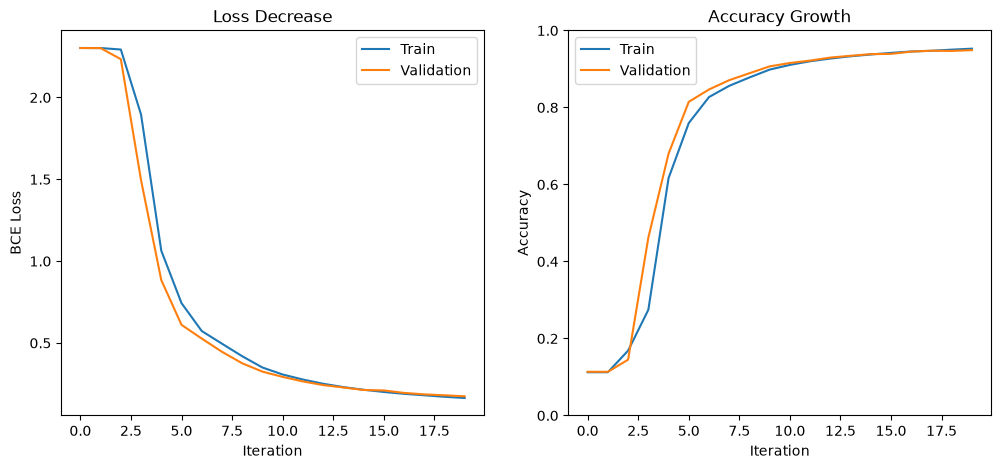

In [8]:
# Plot loss and accuracy curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(num_epochs), losses_train, range(num_epochs), losses_val)
plt.legend(['Train', 'Validation'])
plt.title("Loss Decrease")
plt.xlabel("Iteration")
plt.ylabel("BCE Loss")
plt.subplot(1, 2, 2)
plt.plot(range(num_epochs), accuracies_train, range(num_epochs), accuracies_val)
plt.legend(['Train', 'Validation'])
plt.title("Accuracy Growth")
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

### 5.2. Confusion Matrix

Text(0.5, 1.0, 'Confusion Matrix on Validation Data')

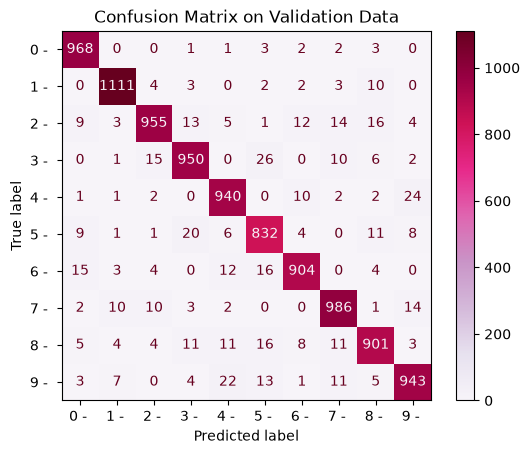

In [9]:
# Confusion Matrix 
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

trimmed_classes = [c[:4] for c in dataset_train.classes] 
cm = confusion_matrix(data_val[1].numpy().argmax(axis=-1), preds_val.argmax(axis=-1))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=trimmed_classes)
disp.plot(cmap=plt.cm.PuRd)
plt.title("Confusion Matrix on Validation Data")

## 6. Test Model

In [13]:
from pathlib import Path

test_dir = Path("test_imgs")
test_dir.mkdir(parents=True, exist_ok=True)
test_img = test_dir / "hwd_raw.jpg"


